## Сегментация частей дерева с помощью CLIPSeg и SAM2

Этот ноутбук реализует двухэтапный пайплайн для точной сегментации различных частей дерева (ствол, листья, дупла) на основе текстовых промптов:

### Основные компоненты:
- **CLIPSeg** - для генерации начальной маски сегментации по текстовому описанию
- **SAM2** - для уточнения и улучшения качества сегментации
- **OpenCV** - для обработки контуров и преобразования масок в полигоны

### Процесс работы:
1. **Инициальная сегментация**: CLIPSeg создает грубую маску по текстовому промпту (например, "trunk", "leaves", "hollow")
2. **Извлечение признаков**: Из начальной маски извлекаются bounding box и ключевые точки
3. **Уточнение SAM2**: SAM2 использует эти признаки для создания точной маски
4. **Постобработка**: Конвертация масок в полигоны для дальнейшего использования

### Возможности:
- Сегментация ствола дерева (`"trunk"`)
- Сегментация листвы (`"leaves"`) 
- Обнаружение дупел (`"hollow"`)
- Визуализация результатов с наложением масок
- Экспорт в формат полигонов

### Применение:
Идеально подходит для детального анализа структуры деревьев, выявления повреждений, мониторинга состояния растительности.

In [1]:
import math
import os
from typing import List, Dict, Any

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from transformers import (
    CLIPSegForImageSegmentation,
    CLIPSegProcessor,
    Sam2Model,
    Sam2Processor,
)

In [2]:
CLIPSEG_ID = "CIDAS/clipseg-rd64"
SAM2_ID = "facebook/sam2-hiera-base-plus"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
def load_models() -> dict:
    models = {}

    models["sam_processor"] = Sam2Processor.from_pretrained(SAM2_ID)
    models["sam_model"] = Sam2Model.from_pretrained(SAM2_ID).to(DEVICE).eval()

    models["clipseg_processor"] = CLIPSegProcessor.from_pretrained(CLIPSEG_ID)
    models["clipseg_model"] = (
        CLIPSegForImageSegmentation.from_pretrained(CLIPSEG_ID).to(DEVICE).eval()
    )

    return models

In [4]:
def generate_initial_mask(
    model: CLIPSegForImageSegmentation,
    processor: CLIPSegProcessor,
    image: Image.Image,
    prompt: str,
    threshold: float = 0.5,
) -> np.ndarray:

    inputs = processor(
        text=[prompt], images=[image.convert("RGB")], return_tensors="pt"
    ).to(DEVICE)

    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.sigmoid(outputs.logits.unsqueeze(1))
        probs_upsampled = F.interpolate(
            probs,
            size=(image.height, image.width),
            mode="bilinear",
            align_corners=False
        )
        prob_map = probs_upsampled.squeeze().cpu().numpy()

    mask = (prob_map >= threshold).astype(np.uint8) * 255
    return mask

In [5]:
def mask_to_bbox(mask: np.ndarray, margin: int = 10) -> list[int] | None:
    ys, xs = np.where(mask > 0)
    if len(xs) == 0:
        return None

    x1 = xs.min()
    x2 = xs.max()
    y1 = ys.min()
    y2 = ys.max()

    x1 = max(0, x1 - margin)
    y1 = max(0, y1 - margin)
    x2 = min(mask.shape[1] - 1, x2 + margin)
    y2 = min(mask.shape[0] - 1, y2 + margin)

    return [int(x1), int(y1), int(x2), int(y2)]

In [6]:
def sample_points_from_mask(mask: np.ndarray, n_points: int = 5) -> list[list[int]]:
    ys, xs = np.where(mask > 0)
    if len(xs) == 0:
        return []
    indices = np.linspace(0, len(xs) - 1, min(n_points, len(xs)), dtype=int)
    
    return [[int(xs[i]), int(ys[i])] for i in indices]

In [7]:
def refine_mask_with_sam(
    pil_image: Image.Image,
    init_mask: np.ndarray,
    sam_model: Sam2Model,
    sam_processor: Sam2Processor,
    box_margin: int = 10,
    n_points: int = 10,
) -> np.ndarray:
    H, W = pil_image.height, pil_image.width
    DEVICE = sam_model.device

    bbox = mask_to_bbox(init_mask, margin=box_margin)
    points = sample_points_from_mask(init_mask, n_points=n_points)

    if bbox is None and not points:
        return init_mask

    proc_kwargs = {"return_tensors": "pt"}
    if bbox is not None:
        proc_kwargs["input_boxes"] = [[bbox]]
    if points:
        proc_kwargs["input_points"] = [[points]]
        proc_kwargs["input_labels"] = [[[1] * len(points)]]

    inputs = sam_processor(pil_image.convert("RGB"), **proc_kwargs).to(DEVICE)

    with torch.no_grad():
        outputs = sam_model(**inputs)

    iou_scores = outputs.iou_scores.cpu().squeeze(0)
    pred_masks_logits = outputs.pred_masks.cpu().squeeze(0)

    best_score = iou_scores.max()
    best_indices = (iou_scores == best_score).nonzero(as_tuple=True)
    query_idx, mask_idx = best_indices[0][0], best_indices[1][0]
    
    best_mask_logits = pred_masks_logits[query_idx, mask_idx]

    upscaled_logits = F.interpolate(
        best_mask_logits.unsqueeze(0).unsqueeze(0),
        size=(H, W),
        mode="bilinear",
        align_corners=False
    ).squeeze()

    refined_mask = (torch.sigmoid(upscaled_logits) > 0.5).numpy().astype(np.uint8) * 255
    
    return refined_mask

In [8]:
def show_mask_overlay(
    image: Image.Image,
    mask: np.ndarray,
    alpha: float = 0.45
) -> None:
    _, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(image)
    ax.imshow(mask, cmap="Reds", alpha=alpha)
    ax.axis("off")
    plt.show()

In [9]:
def mask_to_polygons(
    mask: np.ndarray,
    bbox_origin: List[int]
) -> List[List[List[int]]]:
    contours, _ = cv2.findContours(mask, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
    
    polygons = []
    origin_x, origin_y = bbox_origin[0], bbox_origin[1]

    for contour in contours:
        if len(contour) > 2:
            polygon_points = contour.squeeze(axis=1).tolist()
            
            absolute_polygon = [
                [point[0] + origin_x, point[1] + origin_y] 
                for point in polygon_points
            ]
            polygons.append(absolute_polygon)
            
    return polygons

In [24]:
def show_results(
    image: Image.Image,
    prompt: str,
    initial_mask: np.ndarray,
    refined_mask: np.ndarray,
    alpha: float = 0.5,
):
    image_np = np.array(image)
    
    initial_mask_overlay = np.zeros_like(image_np, dtype=np.uint8)
    initial_mask_overlay[initial_mask > 0] = [255, 0, 0]

    refined_mask_overlay = np.zeros_like(image_np, dtype=np.uint8)
    refined_mask_overlay[refined_mask > 0] = [0, 255, 0]

    # fig, axes = plt.subplots(1, 3, figsize=(20, 8))
    
    # axes[0].imshow(image)
    # axes[0].axis("off")

    # img_with_initial_mask = cv2.addWeighted(image_np, 1, initial_mask_overlay, alpha, 0)
    # axes[1].imshow(img_with_initial_mask)
    # axes[1].axis("off")
    
    # img_with_refined_mask = cv2.addWeighted(image_np, 1, refined_mask_overlay, alpha, 0)
    # axes[2].imshow(img_with_refined_mask)
    # axes[2].axis("off")

    img_with_initial_mask = cv2.addWeighted(image_np, 1, initial_mask_overlay, alpha, 0)
    plt.imshow(img_with_initial_mask)
    plt.axis(False)
    plt.tight_layout()
    plt.show()

In [11]:
models = load_models()

You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.
Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


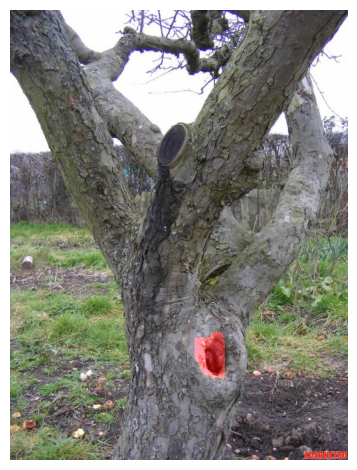

In [25]:
img_path = "test_images/hole3.jpg"
img = Image.open(img_path)
prompt = "hollow"  # "leaves", "hollow", "trunk"

initial_mask = generate_initial_mask(
    models["clipseg_model"], models["clipseg_processor"], img, prompt, threshold=0.35
)

refined_mask = refine_mask_with_sam(
    img, initial_mask, models["sam_model"], models["sam_processor"]
)

show_results(img, prompt, initial_mask, refined_mask)